### Dataset inventory: files per class folder

In [1]:
import os, random, hashlib
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from imutils import paths

path = "../data/raw"
image_paths = list(paths.list_images(path))



In [2]:
ok, corrupted = [], []
for p in image_paths:
    img = cv2.imread(p)
    if img is None:
        corrupted.append(p)
    else:
        ok.append(p)

print(len(ok))  # how many imgs opened fine
print(corrupted)  # the broken ones (empty = good)

7023
[]


### Class distribution

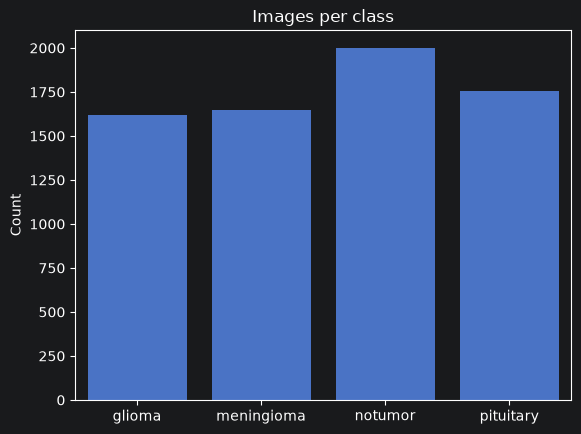

In [3]:
counts = Counter(p.split(os.path.sep)[-2] for p in ok)
sns.barplot(x=list(counts), y=list(counts.values()))
plt.title("Images per class")
plt.ylabel("Count")
plt.show()

### Duplicate analysis: groups, redundant files, cross-class cases

In [4]:
# two files with the same content have the same hash
hashes = {}
for p in ok:
    with open(p, "rb") as f:
        h = hashlib.md5(f.read()).hexdigest()
    hashes.setdefault(h, []).append(p)

dups = [g for g in hashes.values() if len(g) > 1]
extra = sum(len(g) - 1 for g in dups)
cross = [g for g in dups if len({p.split(os.path.sep)[-2] for p in g}) > 1]

print(len(dups))  # nb of duplicate groups
print(extra)  # extra copies we dont need
print(len(cross))  # same img in diff classes (bad)

194
297
0


### Sample images per class

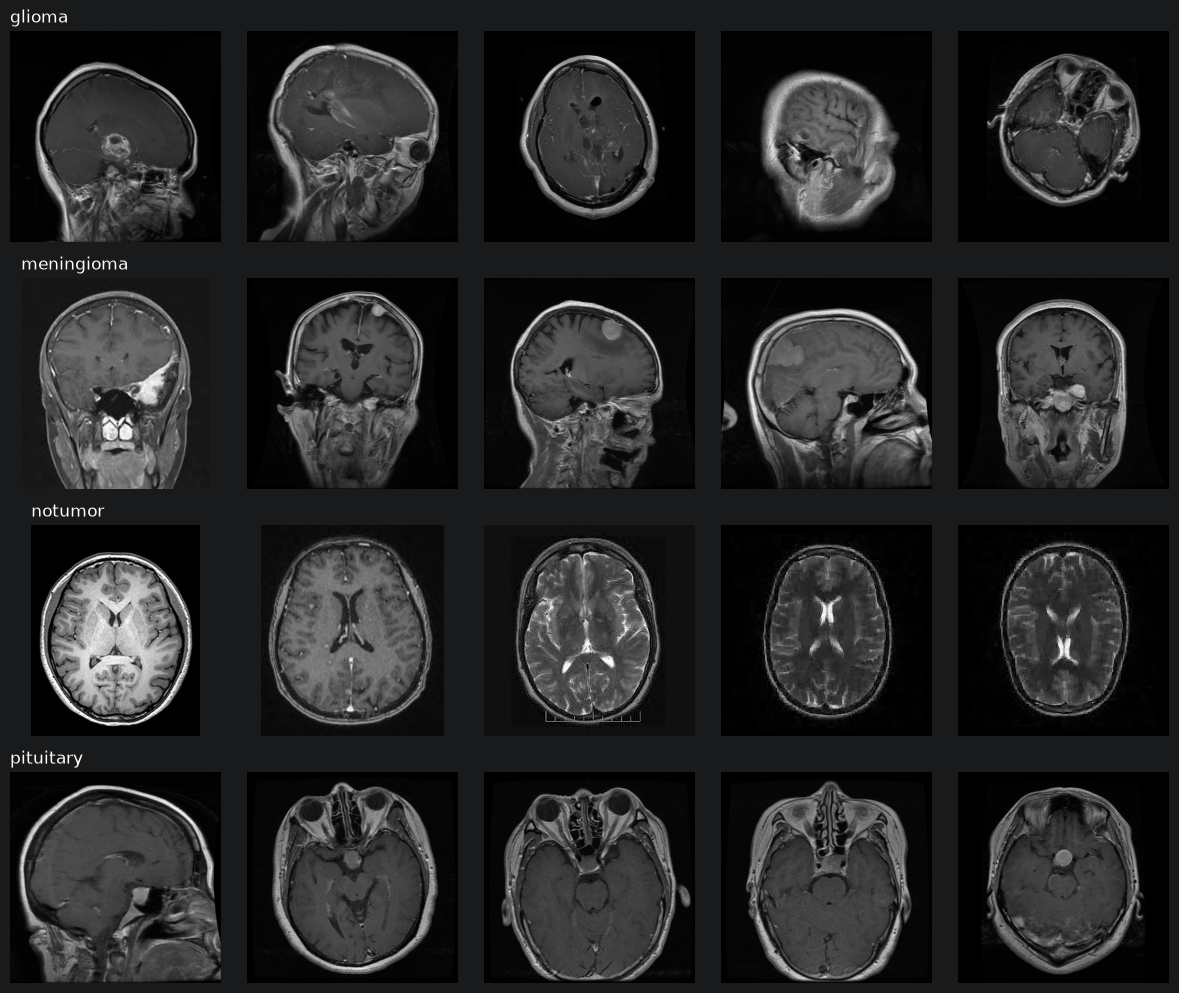

In [5]:
random.seed(42)
classes = sorted(set(p.split(os.path.sep)[-2] for p in ok))

fig, axes = plt.subplots(len(classes), 5, figsize=(12, 10))
for row, cls in enumerate(classes):
    cls_paths = [p for p in ok if p.split(os.path.sep)[-2] == cls]
    for col, p in enumerate(random.sample(cls_paths, 5)):
        img = cv2.imread(p)
        axes[row, col].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        axes[row, col].axis("off")
        if col == 0:
            axes[row, col].set_title(cls, loc="left")
plt.tight_layout()
plt.show()

### Image shapes, channels and pixel range

In [6]:
shapes = Counter()
gray_like = 0
lo, hi = 255, 0
for p in ok:
    img = cv2.imread(p)
    shapes[img.shape] += 1
    if (img[..., 0] == img[..., 1]).all() and (img[..., 1] == img[..., 2]).all():
        gray_like += 1
    lo, hi = min(lo, img.min()), max(hi, img.max())

print(len(shapes))  # how many diff sizes
print(shapes.most_common(5))  # the most commun ones
print(gray_like)  # imgs that look grayscale
print(lo, hi)  # pixel min and max (should be 0 255)

387
[((512, 512, 3), 4742), ((225, 225, 3), 332), ((630, 630, 3), 90), ((236, 236, 3), 81), ((251, 201, 3), 58)]
6894
0 255
